In [ ]:
#import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
#import yaml
import random
from pathlib import Path

print("Environment is ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

Environment is ready!
NumPy: 2.5.3
Pandas: 3.0.5
OpenCV: 5.0.0


In [3]:


dataset_path = Path(
    r"E:\AI_ML PROJECTS\Helmet Detection\data\raw\Helmet and Number Plate Detection for Motorbike Safety.v3i.yolov8"
)

print("Dataset exists:", dataset_path.exists())
print("Dataset path:", dataset_path)

Dataset exists: True
Dataset path: E:\AI_ML PROJECTS\Helmet Detection\data\raw\Helmet and Number Plate Detection for Motorbike Safety.v3i.yolov8


In [4]:
# Dataset ke important folders
train_images = dataset_path / "train" / "images"
train_labels = dataset_path / "train" / "labels"

valid_images = dataset_path / "valid" / "images"
valid_labels = dataset_path / "valid" / "labels"

test_images = dataset_path / "test" / "images"
test_labels = dataset_path / "test" / "labels"

# Count files
print("TRAIN")
print("Images :", len(list(train_images.glob("*.jpg"))))
print("Labels :", len(list(train_labels.glob("*.txt"))))

print("\nVALIDATION")
print("Images :", len(list(valid_images.glob("*.jpg"))))
print("Labels :", len(list(valid_labels.glob("*.txt"))))

print("\nTEST")
print("Images :", len(list(test_images.glob("*.jpg"))))
print("Labels :", len(list(test_labels.glob("*.txt"))))

TRAIN
Images : 11852
Labels : 11852

VALIDATION
Images : 1693
Labels : 1693

TEST
Images : 847
Labels : 847


In [5]:
# Count class distribution in training labels
from collections import Counter

count = Counter()

for file in train_labels.glob("*.txt"):
    with open(file, "r") as f:
        for line in f:
            class_id = int(line.split()[0])
            count[class_id] += 1

print("Helmet:", count[0])
print("No Helmet:", count[1])
print("Number Plate:", count[2])
print("Rider:", count[3])

Helmet: 25717
No Helmet: 11104
Number Plate: 11895
Rider: 14958


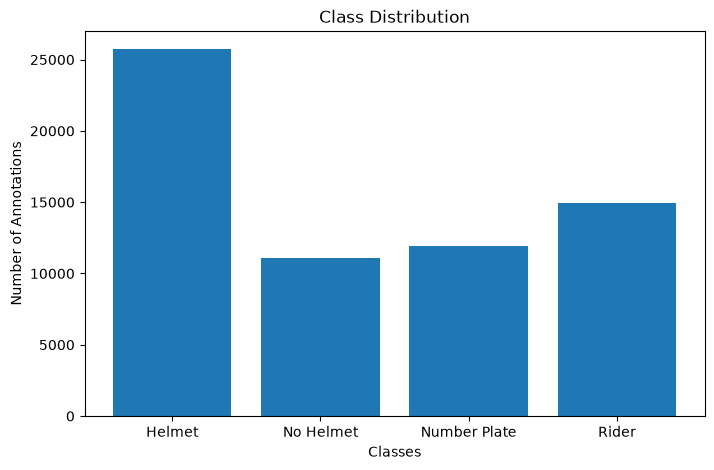

In [6]:
 
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]
counts = [count[0], count[1], count[2], count[3]]


# Bar graph
plt.figure(figsize=(8, 5))

plt.bar(classes, counts)

plt.xlabel("Classes")
plt.ylabel("Number of Annotations")
plt.title("Class Distribution")

plt.show()

In [ ]:
# Empty label files and wrong class IDs check
empty_files = 0
wrong_class = 0
total_files = 0

for file in train_labels.glob("*.txt"):
    total_files += 1

    with open(file, "r") as f:
        lines = f.readlines()

    # Check empty file
    if len(lines) == 0:
        empty_files += 1

    # Check class ID
    for line in lines:
        class_id = int(line.split()[0])

        if class_id not in [0, 1, 2, 3]:
            wrong_class += 1

print("Total label files:", total_files)
print("Empty label files:", empty_files)
print("Wrong class IDs:", wrong_class)

Total label files: 11852
Empty label files: 2
Wrong class IDs: 0


In [9]:
# empty label files
empty_files = []

for file in train_labels.glob("*.txt"):

    with open(file, "r") as f:
        content = f.read().strip()

    if content == "":
        empty_files.append(file.name)

print("Empty label files:")
for file in empty_files:
    print(file)

Empty label files:
test25_mov-0056_jpg.rf.f2bcd2fa32c68ab45d4c9afdfd7f9b5f.txt
test25_mov-0080_jpg.rf.869fc5bb93a2130ab608186fcb8aca39.txt


In [10]:
# match empty label files with corresponding images

for file in empty_files:

    image_name = Path(file).stem + ".jpg"
    image_path = train_images / image_name

    print("Label:", file)
    print("Image :", image_name)
    print("Image exists:", image_path.exists())
    print()

Label: test25_mov-0056_jpg.rf.f2bcd2fa32c68ab45d4c9afdfd7f9b5f.txt
Image : test25_mov-0056_jpg.rf.f2bcd2fa32c68ab45d4c9afdfd7f9b5f.jpg
Image exists: True

Label: test25_mov-0080_jpg.rf.869fc5bb93a2130ab608186fcb8aca39.txt
Image : test25_mov-0080_jpg.rf.869fc5bb93a2130ab608186fcb8aca39.jpg
Image exists: True



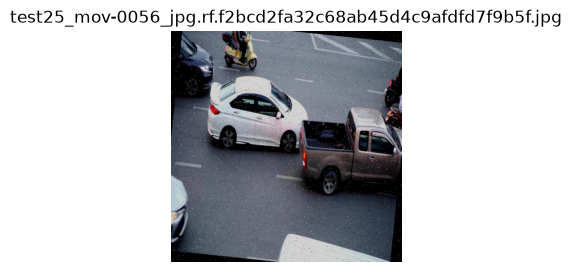

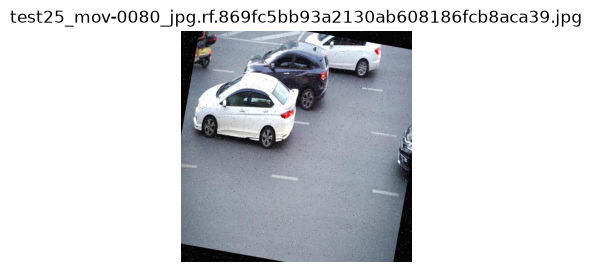

In [11]:
# show images corresponding to empty label files
for file in empty_files:

    image_name = Path(file).stem + ".jpg"
    image_path = train_images / image_name

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4, 3))
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
    plt.show()

In [14]:
# collecting images filenames
image_names = set()

for file in train_images.glob("*.jpg"):
    image_names.add(file.stem)


# collecting labels filenames
label_names = set()

for file in train_labels.glob("*.txt"):
    label_names.add(file.stem)


#  check Difference
missing_labels = image_names - label_names
extra_labels = label_names - image_names


print("Total images:", len(image_names))
print("Total labels:", len(label_names))

print("Images without labels:", len(missing_labels))
print("Labels without images:", len(extra_labels))

Total images: 11852
Total labels: 11852
Images without labels: 0
Labels without images: 0


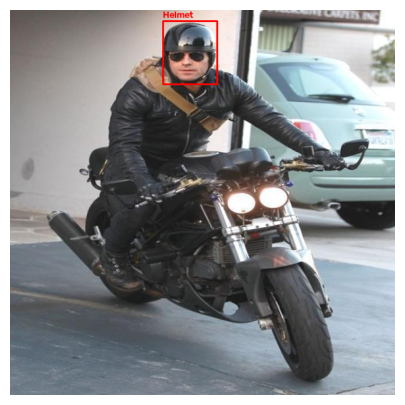

In [15]:


# Ek image select karna
image_file = list(train_images.glob("*.jpg"))[50]

# Us image ka label file
label_file = train_labels / (image_file.stem + ".txt")

# Image read karna
image = cv2.imread(str(image_file))

# OpenCV BGR mein read karta hai, isliye RGB mein convert kar rahe hain
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Image ki height aur width
height, width = image.shape[:2]

# Class names
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

# Label file read karna
with open(label_file, "r") as f:

    for line in f:

        values = line.split()

        class_id = int(values[0])
        x_center = float(values[1])
        y_center = float(values[2])
        box_width = float(values[3])
        box_height = float(values[4])

        # Normalized coordinates ko pixel coordinates mein convert karna
        x_center = int(x_center * width)
        y_center = int(y_center * height)
        box_width = int(box_width * width)
        box_height = int(box_height * height)

        # Bounding box ke corners
        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        # Bounding box draw karna
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        # Class name likhna
        cv2.putText(
            image,
            classes[class_id],
            (x1, y1 - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

# Image show karna
plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

In [16]:
helmet_images = []

for file in train_labels.glob("*.txt"):

    with open(file, "r") as f:
        lines = f.readlines()

    for line in lines:

        class_id = int(line.split()[0])

        if class_id == 0:
            image_file = train_images / (file.stem + ".jpg")
            helmet_images.append(image_file)
            break

    if len(helmet_images) == 10:
        break

print("10 Helmet images found:")

for image in helmet_images:
    print(image.name)

10 Helmet images found:
0_d811f3f2_3788_4245_9106_97507dc8feb6_jpeg_jpg.rf.4857a3271e3ea97cdeaa897c3078a112.jpg
0_d811f3f2_3788_4245_9106_97507dc8feb6_jpeg_jpg.rf.bdd0dac7806169132672966da9c2652f.jpg
1001_jpg.rf.3c7d68b2c9144ab529b35e911093de74.jpg
1001_jpg.rf.f921113281df68ebdd94faa3dd801b39.jpg
1004_jpg.rf.6f926ef26e8358c2d488ad13a8b23381.jpg
1004_jpg.rf.d4f9c2dd28ec05a93f3e8c98267b2094.jpg
1005_jpg.rf.3723dc9a22cdfa4090110da4c913f8a7.jpg
1005_jpg.rf.b102ebede9f0705de56c97dd42d2518b.jpg
1009_jpg.rf.c6fa9a378b1f70cd932f3f061a664642.jpg
1009_jpg.rf.cac8fa40989a7e505dd48d403f005bc9.jpg


In [17]:
no_helmet_rider_images = []

for file in train_labels.glob("*.txt"):

    with open(file, "r") as f:
        lines = f.readlines()

    classes_in_image = []

    for line in lines:
        class_id = int(line.split()[0])
        classes_in_image.append(class_id)

    # Image mein No Helmet + Rider dono hone chahiye
    if 1 in classes_in_image and 3 in classes_in_image:

        image_file = train_images / (file.stem + ".jpg")
        no_helmet_rider_images.append(image_file)

    if len(no_helmet_rider_images) == 10:
        break

print("10 No-Helmet Rider images:")

for image in no_helmet_rider_images:
    print(image.name)

10 No-Helmet Rider images:
BikesHelmets103_png_jpg.rf.1350a63d763f4a35028a51afd54d328a.jpg
BikesHelmets103_png_jpg.rf.5a6d8f9b16e42ec2b085cecad716fde5.jpg
BikesHelmets10_png_jpg.rf.3b61597d7cd80af1b82b83c9f55325fe.jpg
BikesHelmets10_png_jpg.rf.ca708b4204fce8ca33a6211c6b78dd5f.jpg
BikesHelmets112_png_jpg.rf.6653eebcccd3d9203baf240593172dc5.jpg
BikesHelmets112_png_jpg.rf.f3568c09e01bd6742be8eb9c7abc8f04.jpg
BikesHelmets119_png_jpg.rf.3a9ad15139969a51987196a1a48402ca.jpg
BikesHelmets119_png_jpg.rf.e53f5b7eb4e45a41d716da84d4918362.jpg
BikesHelmets137_png_jpg.rf.c6c0927eb4b12f844ea687bdbcf87b77.jpg
BikesHelmets137_png_jpg.rf.fb1d5fd827e0881f6aa6ae5750360136.jpg


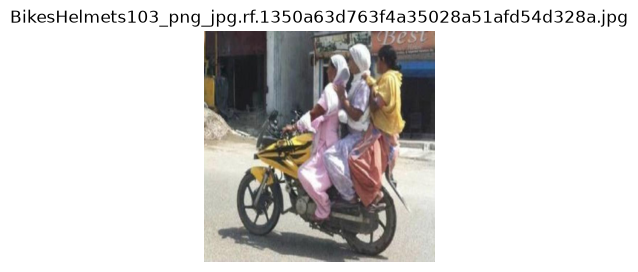

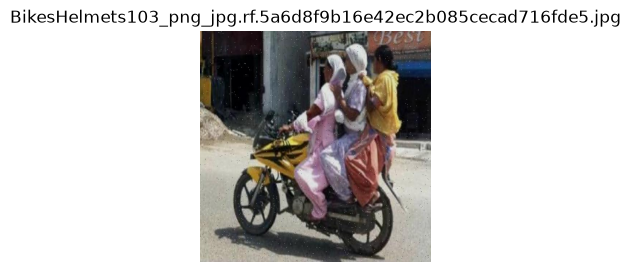

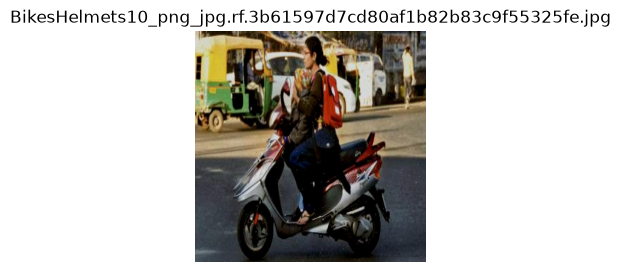

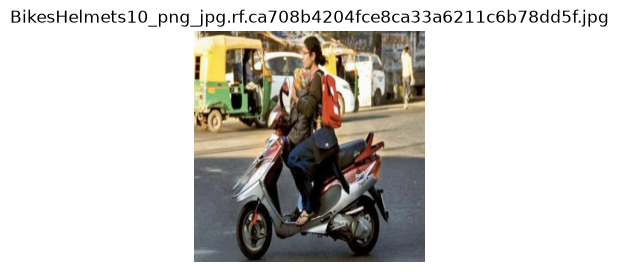

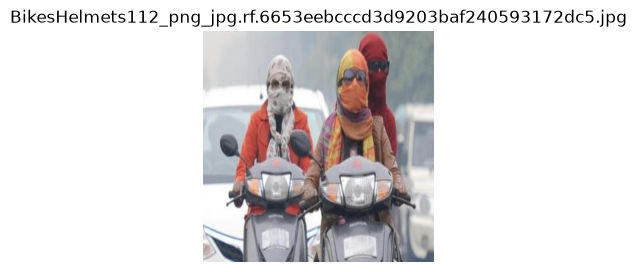

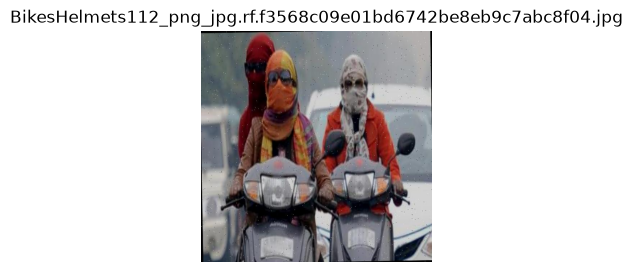

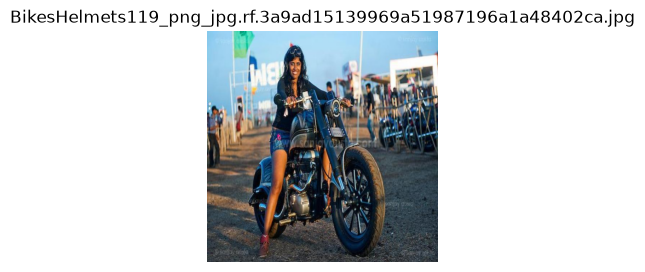

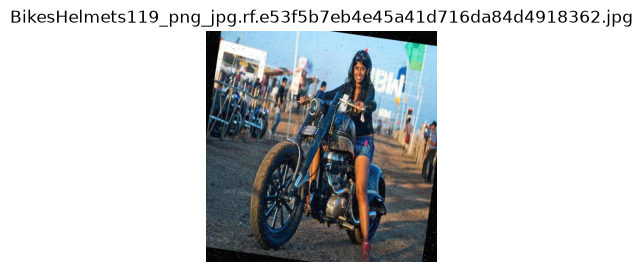

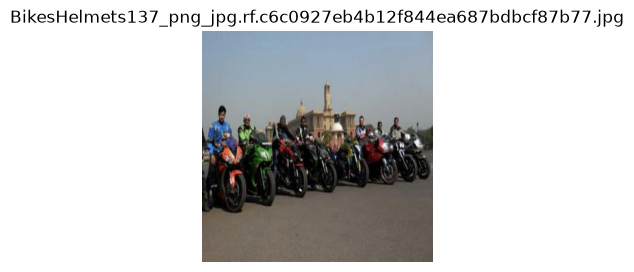

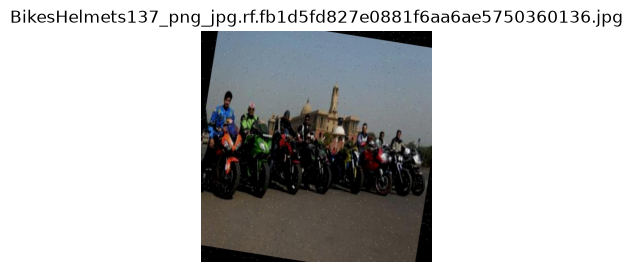

In [18]:
#show images with No Helmet and Rider

for image_file in no_helmet_rider_images:

    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(4, 3))
    plt.imshow(image)
    plt.title(image_file.name)
    plt.axis("off")
    plt.show()

In [19]:
import hashlib

image1 = train_images / "BikesHelmets103_png_jpg.rf.1350a63d763f4a35028a51afd54d328a.jpg"
image2 = train_images / "BikesHelmets103_png_jpg.rf.5a6d8f9b16e42ec2b085cecad716fde5.jpg"

with open(image1, "rb") as f:
    hash1 = hashlib.md5(f.read()).hexdigest()

with open(image2, "rb") as f:
    hash2 = hashlib.md5(f.read()).hexdigest()

print("Image 1:", hash1)
print("Image 2:", hash2)

if hash1 == hash2:
    print("Result: Exact duplicate")
else:
    print("Result: Images are different")

Image 1: 48933e297494fd361d867c040faf3f88
Image 2: fa513f272756681e703dacae1088c99f
Result: Images are different


In [20]:
#check boundry box coordinates
wrong_boxes = 0

for file in train_labels.glob("*.txt"):

    with open(file, "r") as f:

        for line in f:

            values = line.split()

            x = float(values[1])
            y = float(values[2])
            width = float(values[3])
            height = float(values[4])

            if not (0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 <= width <= 1 and
                    0 <= height <= 1):

                wrong_boxes += 1

print("Wrong bounding boxes:", wrong_boxes)

Wrong bounding boxes: 0


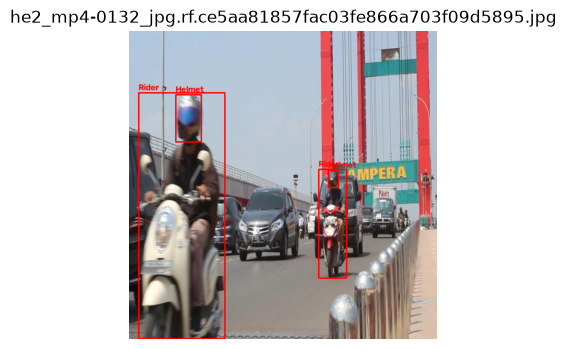

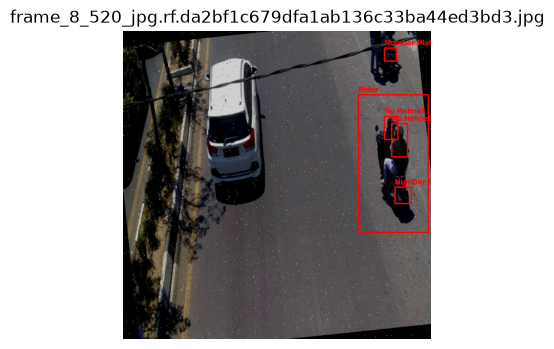

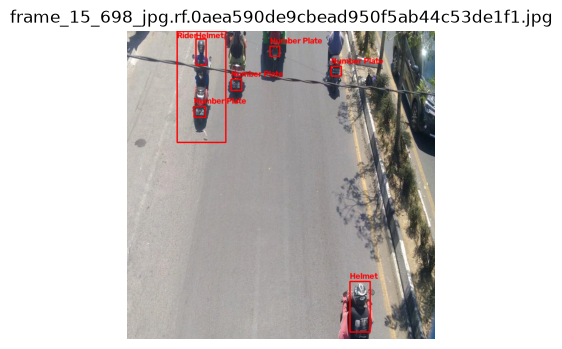

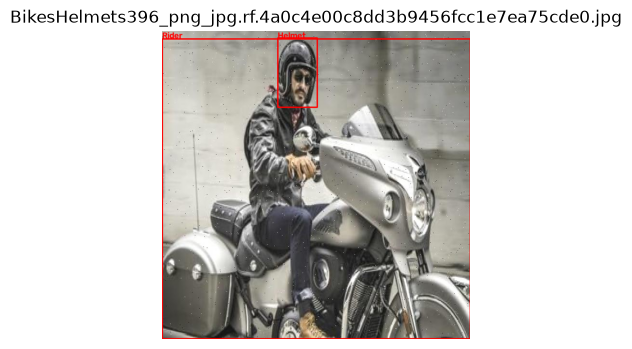

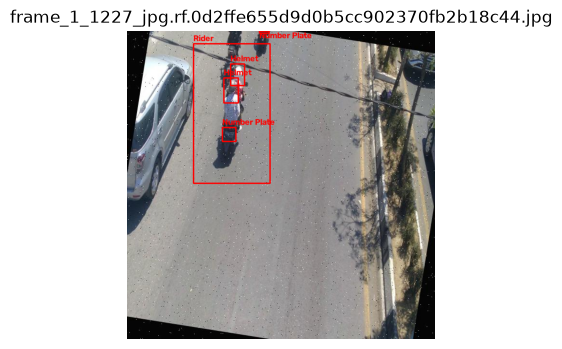

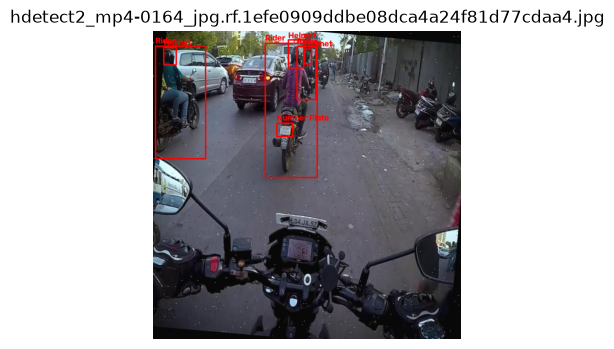

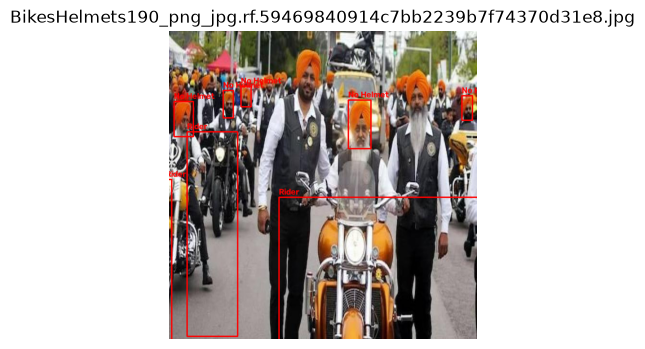

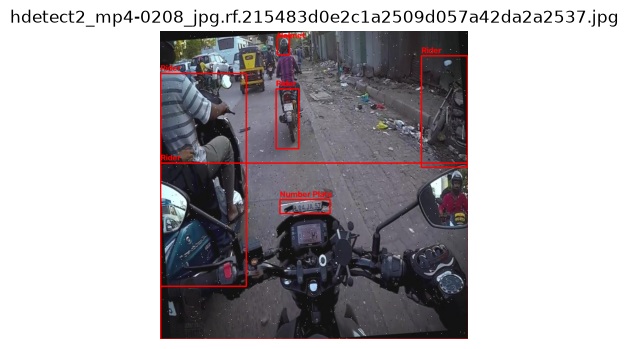

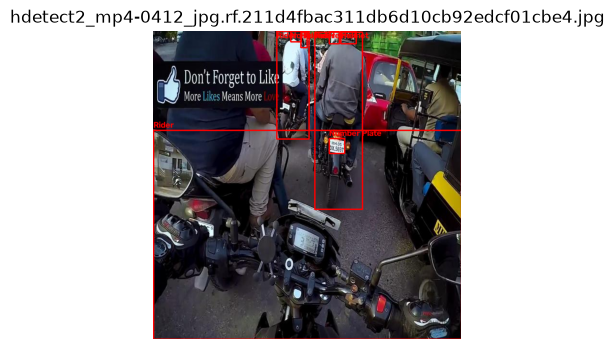

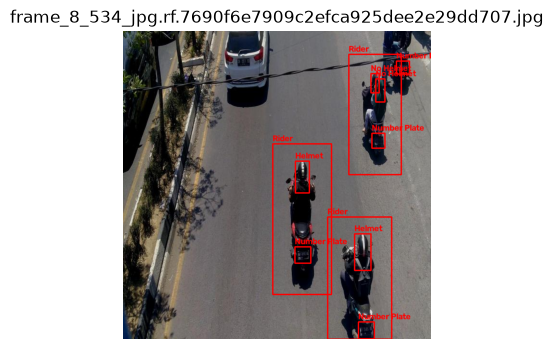

In [21]:


# 10 random images select karna
image_files = random.sample(list(train_images.glob("*.jpg")), 10)

# Class names
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

for image_file in image_files:

    # Image read karna
    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Image ka size
    height, width = image.shape[:2]

    # Corresponding label file
    label_file = train_labels / (image_file.stem + ".txt")

    # Labels read karna
    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            # Normalized coordinates ko pixels mein convert karna
            x_center = int(x_center * width)
            y_center = int(y_center * height)
            box_width = int(box_width * width)
            box_height = int(box_height * height)

            # Bounding box corners
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Box draw karna
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

            # Class name
            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

    # Image show karna
    plt.figure(figsize=(4,4))
    plt.imshow(image)
    plt.title(image_file.name)
    plt.axis("off")
    plt.show()

In [ ]:
# Har folder mein no of images
train_count = len(list(train_images.glob("*.jpg")))
valid_count = len(list(valid_images.glob("*.jpg")))
test_count = len(list(test_images.glob("*.jpg")))

# Total images
total_count = train_count + valid_count + test_count

# Percentage calculate karna
train_percent = (train_count / total_count) * 100
valid_percent = (valid_count / total_count) * 100
test_percent = (test_count / total_count) * 100

print("Train Images:", train_count, f"({train_percent:.2f}%)")
print("Validation Images:", valid_count, f"({valid_percent:.2f}%)")
print("Test Images:", test_count, f"({test_percent:.2f}%)")
print("Total Images:", total_count)

Train Images: 11852 (82.35%)
Validation Images: 1693 (11.76%)
Test Images: 847 (5.89%)
Total Images: 14392


In [22]:
#check class distribution across train, validation, and test sets

from collections import Counter

# Har split ke class annotations count karne ke liye function
def count_classes(label_folder):

    count = Counter()

    for file in label_folder.glob("*.txt"):

        with open(file, "r") as f:

            for line in f:

                values = line.split()

                if len(values) >= 5:
                    class_id = int(values[0])
                    count[class_id] += 1

    return count


# Train, Validation aur Test ke class counts
train_count = count_classes(train_labels)
valid_count = count_classes(valid_labels)
test_count = count_classes(test_labels)


# Class names
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]


# Results print karna
print("TRAIN")
for i, name in enumerate(classes):
    print(name, ":", train_count[i])

print("\nVALIDATION")
for i, name in enumerate(classes):
    print(name, ":", valid_count[i])

print("\nTEST")
for i, name in enumerate(classes):
    print(name, ":", test_count[i])

TRAIN
Helmet : 25717
No Helmet : 11104
Number Plate : 11895
Rider : 14958

VALIDATION
Helmet : 3505
No Helmet : 1691
Number Plate : 1645
Rider : 2122

TEST
Helmet : 1781
No Helmet : 816
Number Plate : 821
Rider : 1040


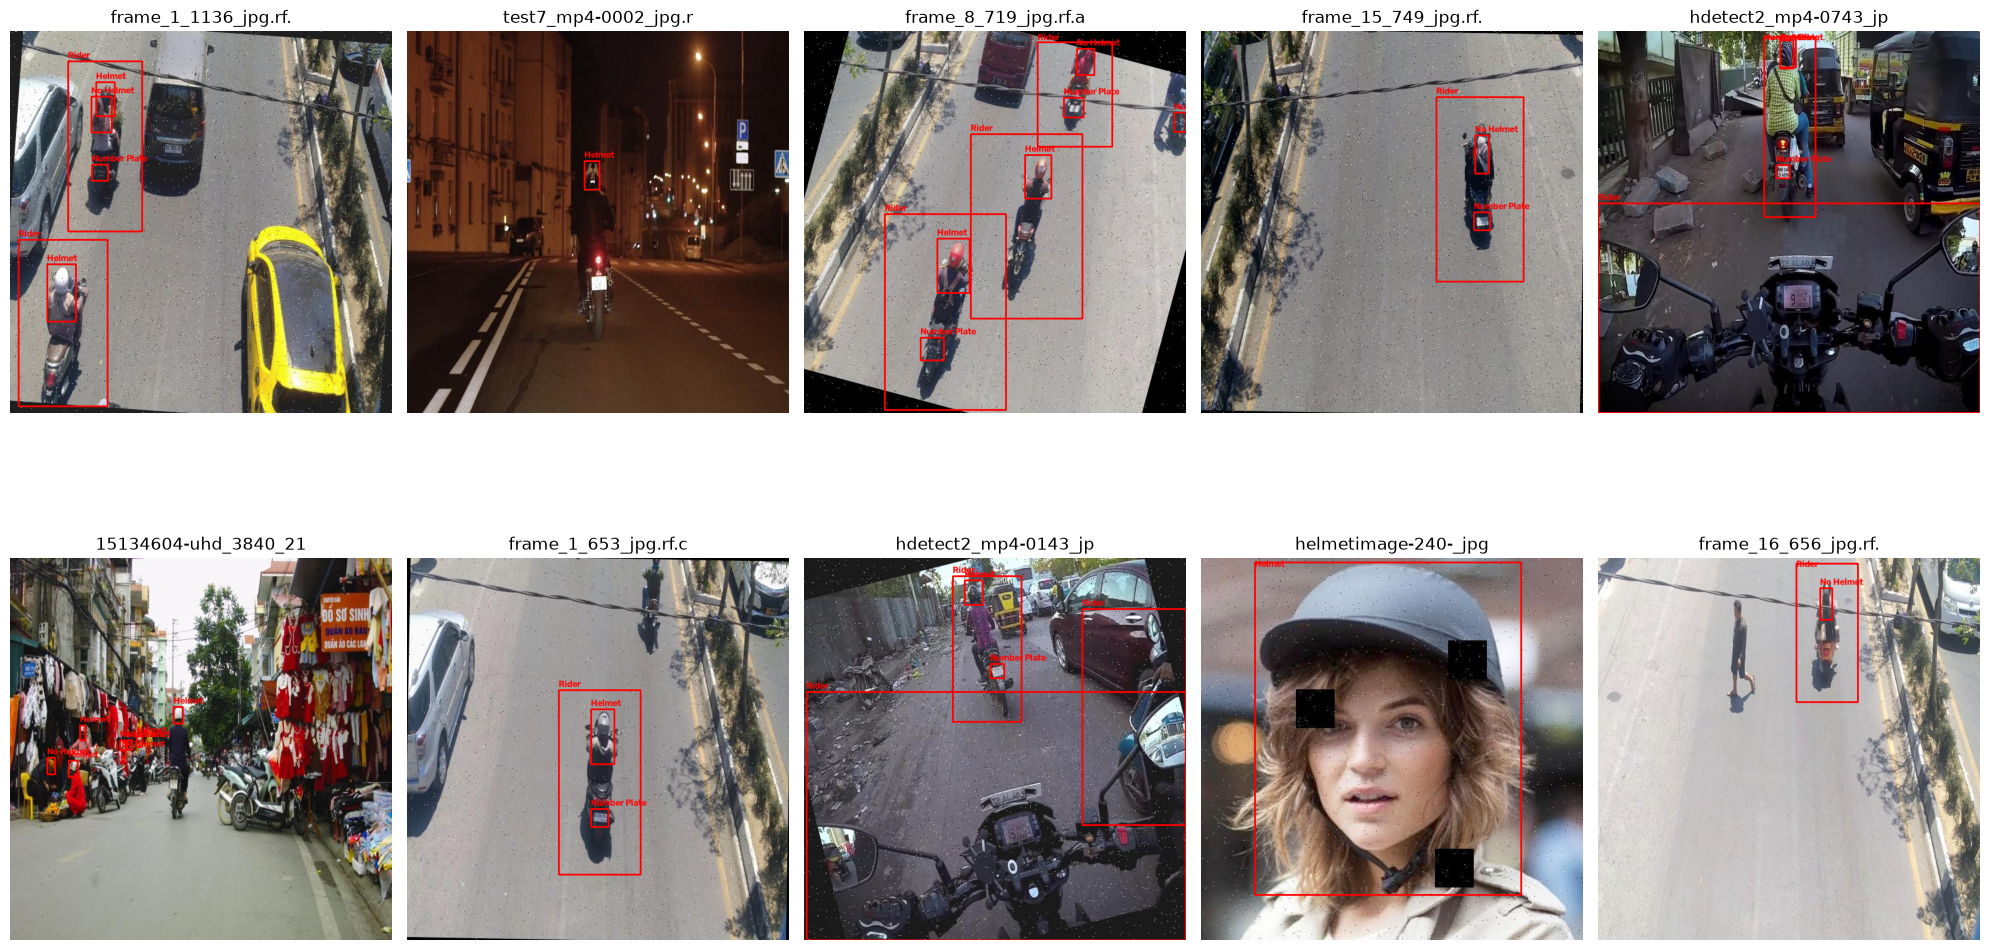

In [23]:


# 10 random images select karna
image_files = random.sample(list(train_images.glob("*.jpg")), 10)

# Class names
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

# 10 images ko display karna
plt.figure(figsize=(20, 12))

for i, image_file in enumerate(image_files):

    # Image read karna
    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Image ka size
    height, width = image.shape[:2]

    # Corresponding label file
    label_file = train_labels / (image_file.stem + ".txt")

    # Labels read karna
    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            # Normalized coordinates → pixel coordinates
            x_center = int(x_center * width)
            y_center = int(y_center * height)
            box_width = int(box_width * width)
            box_height = int(box_height * height)

            # Bounding box corners
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Bounding box draw
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            # Class name draw
            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    # Grid mein image add karna
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:20])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
from collections import Counter

# Sabhi training images ki resolution store karna
image_sizes = []

for image_file in train_images.glob("*.jpg"):

    image = cv2.imread(str(image_file))

    if image is not None:
        height, width = image.shape[:2]
        image_sizes.append((width, height))

# Total valid images
print("Valid images:", len(image_sizes))

# Kitni different resolutions hain
size_counts = Counter(image_sizes)

print("Different resolutions:", len(size_counts))

# Top 10 most common resolutions
print("\nMost common resolutions:")

for size, count in size_counts.most_common(10):
    print(size, ":", count, "images")

Valid images: 11852
Different resolutions: 1

Most common resolutions:
(640, 640) : 11852 images


In [25]:
import hashlib
from collections import defaultdict

# Har image ke hash ko store karne ke liye dictionary
hashes = defaultdict(list)

# Train, Validation aur Test ke images check karna
for split_name, image_folder in [
    ("train", train_images),
    ("valid", valid_images),
    ("test", test_images)
]:

    for image_file in image_folder.glob("*.jpg"):

        # Image ko binary mode mein read karna
        with open(image_file, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        # Hash ke saath image ka naam store karna
        hashes[file_hash].append((split_name, image_file.name))


# Duplicate groups find karna
duplicate_groups = [
    files for files in hashes.values()
    if len(files) > 1
]

print("Total unique hash groups:", len(hashes))
print("Duplicate groups:", len(duplicate_groups))

Total unique hash groups: 14391
Duplicate groups: 1


In [26]:
for group in duplicate_groups:
    print("\nDuplicate group:")

    for split_name, image_name in group:
        print(split_name, "→", image_name)
        


Duplicate group:
train → frame_3_1411_jpg.rf.14c8bbc8a5f246e307ab44064524cb0f.jpg
train → frame_3_1411_jpg.rf.6a0224f391e62880f99ed8661897aae4.jpg


In [ ]:


# Cleaned dataset
DATASET = Path(r"E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned")

for split in ["train", "valid", "test"]:
    image_dir = DATASET / split / "images"
    label_dir = DATASET / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print(f"Images : {len(images)}")
    print(f"Labels : {len(labels)}")


TRAIN
Images : 11852
Labels : 11874

VALID
Images : 1693
Labels : 1693

TEST
Images : 847
Labels : 847


In [29]:

DATASET = Path(r"E:\AI_ML PROJECTS\Helmet Detection\data\cleaned\helmet_dataset_cleaned")

image_dir = DATASET / "train" / "images"
label_dir = DATASET / "train" / "labels"

image_stems = {p.stem for p in image_dir.iterdir() if p.is_file()}
label_stems = {p.stem for p in label_dir.glob("*.txt")}

missing_images = sorted(label_stems - image_stems)
missing_labels = sorted(image_stems - label_stems)

print("Labels without corresponding image:", len(missing_images))
print("Images without corresponding label:", len(missing_labels))

print("\nExtra labels:")
for x in missing_images:
    print(x)

print("\nImages without labels:")
for x in missing_labels:
    print(x)

Labels without corresponding image: 22
Images without corresponding label: 0

Extra labels:
frame_15_674_jpg.rf.e65c57c2bbee987b85b3f9ea82bdba3e (1)
frame_15_674_jpg.rf.ffbf2b7240ada899d921e30e271c21be (1)
frame_15_675_jpg.rf.44dbae1a658f116fb27ecf39efda4ae3 (1)
frame_15_675_jpg.rf.46f6f84f5b528942c98d5ea37194bf59 (1)
frame_15_675_jpg.rf.72a032caff95148cc0215827984d3f6b (1)
frame_15_675_jpg.rf.9882adcb6056d2e81ca4718dfa5f206e (1)
frame_1_1080_jpg.rf.c84b511110b805c9ac02235a1e5d75af (1)
frame_1_1080_jpg.rf.cd8578e2a7da4bcd5190e044a2daa922 (1)
frame_1_1081_jpg.rf.10f36169a57ea5aef83f4b000f4a6a84 (1)
frame_1_1081_jpg.rf.27211b7e52c099d86f846d00b2e70158 (1)
frame_1_1081_jpg.rf.4a18928214597b592015d1eb289984cf (1)
frame_1_1081_jpg.rf.68cea40fd90c2e9f6febc0f0ca5d4918 (1)
frame_1_1081_jpg.rf.79519f0fa39805db38db5ff59e31737f (1)
frame_1_1081_jpg.rf.9c5a3c0295b8bd8afdf3c765558f8d8f (1)
frame_1_1082_jpg.rf.1c04c349f5662a7bd3bc691a628e12ba (1)
frame_1_1082_jpg.rf.4498686f9e69575b77f565ee4cb526a5 

In [30]:

label_dir = DATASET / "train" / "labels"

extra_labels = sorted(label_stems - image_stems)

print("Extra label files:", len(extra_labels))
print("\nDetails:\n")

for stem in extra_labels:
    label_file = label_dir / f"{stem}.txt"
    
    print("=" * 80)
    print(stem)
    print("Exists:", label_file.exists())
    
    if label_file.exists():
        with open(label_file, "r") as f:
            lines = f.readlines()
        
        print("Number of annotations:", len(lines))
        print("First annotations:")
        for line in lines[:5]:
            print(line.strip())

Extra label files: 22

Details:

frame_15_674_jpg.rf.e65c57c2bbee987b85b3f9ea82bdba3e (1)
Exists: True
Number of annotations: 14
First annotations:
3 0.30625 0.22890625 0.246875 0.41875
2 0.28359375 0.3203125 0.05 0.0515625
0 0.315625 0.128125 0.04375 0.0890625
2 0.5171875 0.3671875 0.05 0.0546875
3 0.3328125 0.490625 0.2609375 0.4703125
frame_15_674_jpg.rf.ffbf2b7240ada899d921e30e271c21be (1)
Exists: True
Number of annotations: 14
First annotations:
3 0.30625 0.22890625 0.246875 0.41875
2 0.28359375 0.3203125 0.05 0.0515625
0 0.315625 0.128125 0.04375 0.0890625
2 0.5171875 0.3671875 0.05 0.0546875
3 0.3328125 0.490625 0.2609375 0.4703125
frame_15_675_jpg.rf.44dbae1a658f116fb27ecf39efda4ae3 (1)
Exists: True
Number of annotations: 14
First annotations:
3 0.2703125 0.23671875 0.1734375 0.403125
2 0.265625 0.33359375 0.04375 0.0515625
0 0.26953125 0.140625 0.03515625 0.08828125
2 0.4984375 0.3515625 0.04609375 0.0453125
3 0.3359375 0.48671875 0.1953125 0.48125
frame_15_675_jpg.rf.46f6f84f

In [31]:
# Remove only label files that have no corresponding image

removed = []

for stem in missing_images:
    label_file = label_dir / f"{stem}.txt"

    if label_file.exists():
        label_file.unlink()
        removed.append(stem)

print("Removed labels:", len(removed))

for x in removed:
    print(x)

Removed labels: 22
frame_15_674_jpg.rf.e65c57c2bbee987b85b3f9ea82bdba3e (1)
frame_15_674_jpg.rf.ffbf2b7240ada899d921e30e271c21be (1)
frame_15_675_jpg.rf.44dbae1a658f116fb27ecf39efda4ae3 (1)
frame_15_675_jpg.rf.46f6f84f5b528942c98d5ea37194bf59 (1)
frame_15_675_jpg.rf.72a032caff95148cc0215827984d3f6b (1)
frame_15_675_jpg.rf.9882adcb6056d2e81ca4718dfa5f206e (1)
frame_1_1080_jpg.rf.c84b511110b805c9ac02235a1e5d75af (1)
frame_1_1080_jpg.rf.cd8578e2a7da4bcd5190e044a2daa922 (1)
frame_1_1081_jpg.rf.10f36169a57ea5aef83f4b000f4a6a84 (1)
frame_1_1081_jpg.rf.27211b7e52c099d86f846d00b2e70158 (1)
frame_1_1081_jpg.rf.4a18928214597b592015d1eb289984cf (1)
frame_1_1081_jpg.rf.68cea40fd90c2e9f6febc0f0ca5d4918 (1)
frame_1_1081_jpg.rf.79519f0fa39805db38db5ff59e31737f (1)
frame_1_1081_jpg.rf.9c5a3c0295b8bd8afdf3c765558f8d8f (1)
frame_1_1082_jpg.rf.1c04c349f5662a7bd3bc691a628e12ba (1)
frame_1_1082_jpg.rf.4498686f9e69575b77f565ee4cb526a5 (1)
frame_1_1082_jpg.rf.65e347d2190a24e1f70ab8c3990036d6 (1)
frame_1_1082

In [32]:
for split in ["train", "valid", "test"]:
    image_dir = DATASET / split / "images"
    label_dir = DATASET / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print(f"Images : {len(images)}")
    print(f"Labels : {len(labels)}")


TRAIN
Images : 11852
Labels : 11852

VALID
Images : 1693
Labels : 1693

TEST
Images : 847
Labels : 847
